In [9]:
!pip install FRECKLL acepython -q

In [10]:
import numpy as np
import json
import os
from astropy import units as u
from tqdm import tqdm

from freckll.io.loader import default_network_loader
from freckll.ace import equil_chemistry_ace
from freckll.solver import Rosenbrock

In [11]:
np.random.seed(42)
N=50
T_arr = np.random.uniform(500.0, 2500.0, N)
Rp_arr = np.random.uniform(0.5, 2.0, N)
Mp_arr = np.random.uniform(0.3, 13.0, N)
Rstar_arr = np.random.uniform(0.5, 2.0, N)
log_Kzz_arr = np.random.uniform(4.0, 12.0, N)
Kzz_arr = 10 ** log_Kzz_arr

print(f"T range:      {T_arr.min():.0f} — {T_arr.max():.0f} K")
print(f"Rp range:     {Rp_arr.min():.2f} — {Rp_arr.max():.2f} Rjup")
print(f"Mp range:     {Mp_arr.min():.2f} — {Mp_arr.max():.2f} Mjup")
print(f"Rstar range:  {Rstar_arr.min():.2f} — {Rstar_arr.max():.2f} Rsun")
print(f"log_Kzz range: {np.log10(Kzz_arr).min():.1f} — {np.log10(Kzz_arr).max():.1f}")

T range:      541 — 2440 K
Rp range:     0.51 — 1.98 Rjup
Mp range:     0.39 — 12.64 Mjup
Rstar range:  0.52 — 1.98 Rsun
log_Kzz range: 4.0 — 11.8


In [12]:
network = default_network_loader("venot-methanol-2020-reduced")
print("Network loaded. Species:", len(network.species))

Network loaded. Species: 44


In [13]:
n_layers = 100
pressure = np.logspace(2, -5, n_layers) << u.bar

print(f"Pressure grid: {pressure[0]:.1e} to {pressure[-1]:.1e}")
print(f"Shape: {pressure.shape}")

Pressure grid: 1.0e+02 bar to 1.0e-05 bar
Shape: (100,)


In [14]:
os.makedirs("freckll_profiles", exist_ok=True)

In [15]:
import warnings
import scipy.sparse.linalg as spla

# MatrixRankWarning floods output during Rosenbrock solves — safe to suppress
warnings.filterwarnings("ignore", category=spla.MatrixRankWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning,
                        message="divide by zero encountered in scalar divide")

In [16]:
successful_indices = []
failed_indices = []
for i in tqdm(range(N),desc="Generating FRECKLL profiles"):
  T_val = T_arr[i]
  Rp_val = Rp_arr[i]
  Mp_val = Mp_arr[i]
  Kzz_val = Kzz_arr[i]
  try:
    temperature = np.full(n_layers, T_val) << u.K
    kzz = np.full(n_layers, Kzz_val) << u.cm**2 / u.s
    equil_vmr = equil_chemistry_ace(temperature=temperature,pressure=pressure,composition=network.species,
                                    elements=["H", "He", "C", "N", "O"],abundances=[12, 10.93, 8.39, 7.86, 8.73])
    solver = Rosenbrock(network=network)
    solver.set_system_parameters(temperature=temperature,pressure=pressure,kzz=kzz,planet_radius=Rp_val * u.Rjup,planet_mass=Mp_val * u.Mjup)
    result = solver.solve(equil_vmr,t_span=[0,1e16],enable_diffusion=True,maxiter=2000,rtol=1e-4,atol=1e-20)
    if not result["success"]:
      failed_indices.append(i)
      continue

    species_names = [str(s) for s in result["species"]]
    final_vmr = result["vmr"][-1]
    def get_vmr(mol):
      idx = species_names.index(mol)
      return np.array(final_vmr[idx])

    profiles = {
            "H2O": get_vmr("H2O"),
            "CH4": get_vmr("CH4"),
            "CO":  get_vmr("CO"),
            "CO2": get_vmr("CO2"),
            "NH3": get_vmr("NH3"),
        }
    np.savez(
            f"freckll_profiles/profile_{i:04d}.npz",
            h2o=profiles["H2O"],
            ch4=profiles["CH4"],
            co=profiles["CO"],
            co2=profiles["CO2"],
            nh3=profiles["NH3"],
    )
    successful_indices.append(i)
    saved = len([f for f in os.listdir("freckll_profiles") if f.endswith(".npz")])
    print(f"Profiles saved so far: {saved} / {N}")
  except Exception as e:
    print(f"\n[WARNING] Run {i} failed: {e}")
    failed_indices.append(i)
    continue
print(f"\nDone! Successful: {len(successful_indices)}, Failed: {len(failed_indices)}")


Generating FRECKLL profiles:   2%|▏         | 1/50 [00:13<10:48, 13.23s/it]

Profiles saved so far: 1 / 50


/usr/local/lib/python3.12/dist-packages/freckll/solver/solver.py:102: RuntimeWarning: invalid value encountered in scalar divide
  dydt = dy / (t[-1] - t[-2])
Generating FRECKLL profiles:   6%|▌         | 3/50 [13:15<3:27:00, 264.26s/it]

Profiles saved so far: 2 / 50


Generating FRECKLL profiles:   8%|▊         | 4/50 [13:40<2:10:12, 169.84s/it]

...

Profiles saved so far: 42 / 50


Generating FRECKLL profiles:  98%|█████████▊| 49/50 [1:19:10<00:49, 49.02s/it]

Profiles saved so far: 43 / 50


Generating FRECKLL profiles: 100%|██████████| 50/50 [1:19:18<00:00, 95.17s/it]

Profiles saved so far: 44 / 50

Done! Successful: 44, Failed: 6


In [17]:
params = {
    "T":       T_arr.tolist(),
    "Rp_Rj":   Rp_arr.tolist(),
    "Mp_Mj":   Mp_arr.tolist(),
    "Rstar_Rs": Rstar_arr.tolist(),
    "log_Kzz": np.log10(Kzz_arr).tolist(),
    "successful_indices": successful_indices,
    "failed_indices": failed_indices,
}

with open("freckll_profiles/params.json", "w") as f:
    json.dump(params, f, indent=2)

print("Saved params.json")
print(f"Final count — Successful: {len(successful_indices)}, Failed: {len(failed_indices)}")

Saved params.json
Final count — Successful: 44, Failed: 6


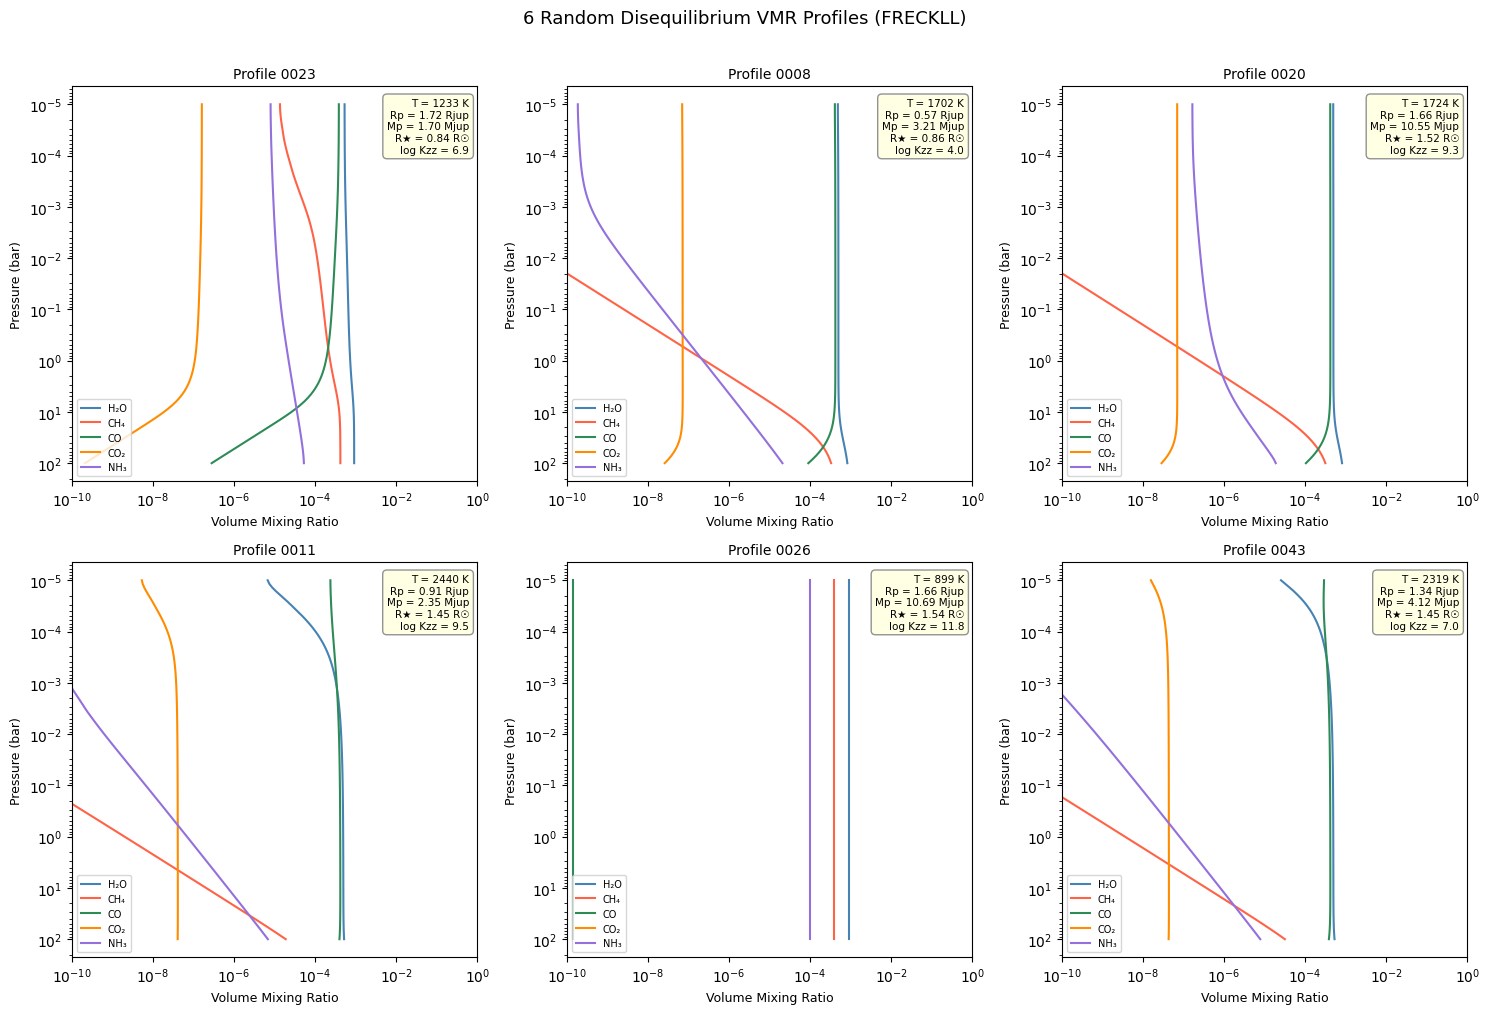

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import os
import json
import random

# Load parameter table
with open("freckll_profiles/params.json", "r") as f:
    params = json.load(f)

# Pick 6 random completed profiles
saved_files = [f for f in os.listdir("freckll_profiles") if f.endswith(".npz")]
chosen = random.sample(saved_files, min(6, len(saved_files)))

# FRECKLL pressure grid
freckll_P = np.logspace(2, -5, 100)

molecules  = ["h2o", "ch4", "co", "co2", "nh3"]
mol_labels = ["H₂O", "CH₄", "CO", "CO₂", "NH₃"]
colors     = ["steelblue", "tomato", "seagreen", "darkorange", "mediumpurple"]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, fname in zip(axes, chosen):
    data = np.load(f"freckll_profiles/{fname}")
    idx  = int(fname.replace("profile_", "").replace(".npz", ""))

    # Pull parameters for this profile
    T        = params["T"][idx]
    Rp       = params["Rp_Rj"][idx]
    Mp       = params["Mp_Mj"][idx]
    Rstar    = params["Rstar_Rs"][idx]
    log_Kzz  = params["log_Kzz"][idx]

    for mol, label, color in zip(molecules, mol_labels, colors):
        ax.plot(data[mol], freckll_P, label=label, color=color, linewidth=1.5)

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.invert_yaxis()
    ax.set_xlabel("Volume Mixing Ratio", fontsize=9)
    ax.set_ylabel("Pressure (bar)", fontsize=9)
    ax.legend(fontsize=7, loc="lower left")
    ax.set_xlim(1e-10, 1e0)

    # Parameter box in top-right corner
    param_text = (
        f"T = {T:.0f} K\n"
        f"Rp = {Rp:.2f} Rjup\n"
        f"Mp = {Mp:.2f} Mjup\n"
        f"R★ = {Rstar:.2f} R☉\n"
        f"log Kzz = {log_Kzz:.1f}"
    )
    ax.text(
        0.98, 0.97, param_text,
        transform=ax.transAxes,
        fontsize=7.5,
        verticalalignment="top",
        horizontalalignment="right",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="lightyellow", alpha=0.85, edgecolor="gray")
    )

    ax.set_title(f"Profile {idx:04d}", fontsize=10)

plt.suptitle("6 Random Disequilibrium VMR Profiles (FRECKLL)", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [19]:
from google.colab import files
import zipfile

# Zip everything up
with zipfile.ZipFile("freckll_profiles.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for fname in os.listdir("freckll_profiles"):
        zf.write(f"freckll_profiles/{fname}")

files.download("freckll_profiles.zip")
print("Download triggered!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered!
